# **Customer Churn Analysis**
Identify customer characteristics associated with higher churn to support retention decisions.

**Dataset:** IBM Telco Customer Churn (7,043 customers, 21 columns)

**Tools:** Python, pandas, matplotlib, seaborn

## Business Objective

Understand customer churn patterns and identify customer characteristics associated with a higher likelihood of leaving the telecommunications service.

## Contents

1. Setup & Load Data
2. Data Quality Audit
3. Data Cleaning
4. Overall Churn Rate
5. Churn Drivers
6. Key Findings
7. Recommendations
8. Limitations and Assumptions

## 1. Setup & Load Data
Import libraries and load the dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)

print("Shape:", df.shape)
df.head()

Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Data Quality Audit
Check data types, missing values, duplicates, blank strings, and category consistency before any analysis.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0], "\n")
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate customerID:", df["customerID"].duplicated().sum(), "\n")

blank = df.select_dtypes("object").apply(lambda s: s.str.strip().eq("").sum())
print("Blank strings per column:\n", blank[blank > 0])

Missing values:
 Series([], dtype: int64) 

Duplicate rows: 0
Duplicate customerID: 0 

Blank strings per column:
 TotalCharges    11
dtype: int64


C:\Users\qwwer\AppData\Local\Temp\ipykernel_8544\3493722854.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  blank = df.select_dtypes("object").apply(lambda s: s.str.strip().eq("").sum())


In [4]:
for col in df.select_dtypes("object").columns.drop(["customerID", "TotalCharges"]):
    print(f"{col}: {df[col].unique().tolist()}")

df.describe()

gender: ['Female', 'Male']
Partner: ['Yes', 'No']
Dependents: ['No', 'Yes']
PhoneService: ['No', 'Yes']
MultipleLines: ['No phone service', 'No', 'Yes']
InternetService: ['DSL', 'Fiber optic', 'No']
OnlineSecurity: ['No', 'Yes', 'No internet service']
OnlineBackup: ['Yes', 'No', 'No internet service']
DeviceProtection: ['No', 'Yes', 'No internet service']
TechSupport: ['No', 'Yes', 'No internet service']
StreamingTV: ['No', 'Yes', 'No internet service']
StreamingMovies: ['No', 'Yes', 'No internet service']
Contract: ['Month-to-month', 'One year', 'Two year']
PaperlessBilling: ['Yes', 'No']
PaymentMethod: ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn: ['No', 'Yes']


C:\Users\qwwer\AppData\Local\Temp\ipykernel_8544\662695444.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes("object").columns.drop(["customerID", "TotalCharges"]):


,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 3. Data Cleaning
Fix `TotalCharges`, standardize `SeniorCitizen`, and create the derived columns needed for analysis (`Churn_flag`, `tenure_group`, `monthly_group`). The raw `df` is kept untouched; all changes go into `df_clean`.

In [5]:
# Are the blank TotalCharges values all new customers (tenure = 0)?
blank = df["TotalCharges"].str.strip() == ""

print("Blank TotalCharges:", blank.sum())
print("Customers with tenure = 0:", (df["tenure"] == 0).sum())
print("Both conditions:", (blank & (df["tenure"] == 0)).sum())

Blank TotalCharges: 11
Customers with tenure = 0: 11
Both conditions: 11


In [6]:
df_clean = df.copy()

# TotalCharges: blank = new customer not yet billed, so fill with 0
df_clean["TotalCharges"] = pd.to_numeric(df_clean["TotalCharges"], errors="coerce").fillna(0)

# SeniorCitizen: 0/1 -> No/Yes, consistent with other columns
df_clean["SeniorCitizen"] = df_clean["SeniorCitizen"].map({0: "No", 1: "Yes"})

# Churn as 1/0, so the average = churn rate
df_clean["Churn_flag"] = df_clean["Churn"].map({"Yes": 1, "No": 0})

# Tenure groups (in months)
df_clean["tenure_group"] = pd.cut(
    df_clean["tenure"],
    bins=[0, 12, 24, 48, 60, 72],
    labels=["0-12", "13-24", "25-48", "49-60", "61-72"],
    include_lowest=True,
)

# Monthly charges groups
df_clean["monthly_group"] = pd.cut(
    df_clean["MonthlyCharges"],
    bins=[0, 35, 70, 90, 120],
    labels=["<=35", "35-70", "70-90", ">90"],
)

In [7]:
print("Shape:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())
print("TotalCharges = 0:", (df_clean["TotalCharges"] == 0).sum())

print("\nTenure groups:")
print(df_clean["tenure_group"].value_counts().sort_index())

print("\nMonthly charges groups:")
print(df_clean["monthly_group"].value_counts().sort_index())

print("\nOverall churn rate (%):", round(df_clean["Churn_flag"].mean() * 100, 2))

Shape: (7043, 24)
Missing values: 0
TotalCharges = 0: 11

Tenure groups:
tenure_group
0-12     2186
13-24    1024
25-48    1594
49-60     832
61-72    1407
Name: count, dtype: int64

Monthly charges groups:
monthly_group
<=35     1735
35-70    1725
70-90    1844
>90      1739
Name: count, dtype: int64

Overall churn rate (%): 26.54


### Cleaning summary
- **Missing values / duplicates:** none found.
- **TotalCharges:** 11 blank values, all belonging to customers with tenure = 0 (new customers not yet billed). Converted to numeric and filled with 0.
- **SeniorCitizen:** converted from 0/1 to No/Yes for consistency.
- **New columns:** `Churn_flag` (1/0), `tenure_group`, `monthly_group`.
- **Add-on columns:** "No internet service" is kept separate from "No" (these customers cannot subscribe to add-ons).

## 4. Overall Churn Rate
How many customers left, and what share of the customer base does that represent? This is the baseline for every comparison that follows.

In [8]:
overall_rate = df_clean["Churn_flag"].mean() * 100

print(f"Total customers: {len(df_clean):,}")
print(f"Churned customers: {df_clean['Churn_flag'].sum():,}")
print(f"Overall churn rate: {overall_rate:.2f}%")

Total customers: 7,043
Churned customers: 1,869
Overall churn rate: 26.54%


## 5. Churn Drivers
Each segment is compared against the overall churn rate (red dashed line in the charts).

### 5.1 Churn by Contract Type

,customers,churn_rate
Contract,,
Month-to-month,3875,42.7
One year,1473,11.3
Two year,1695,2.8


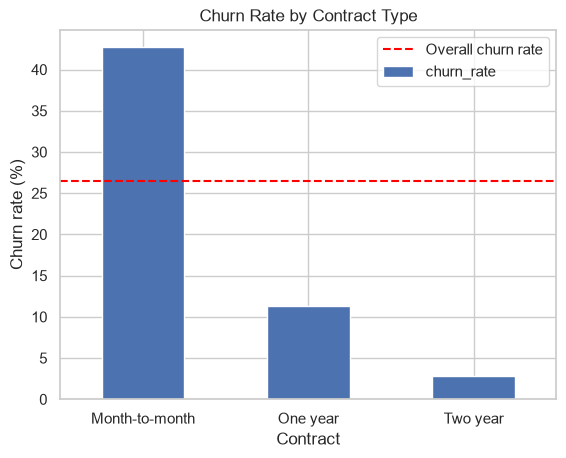

In [9]:
# Churn rate by contract type
contract = df_clean.groupby("Contract")["Churn_flag"].agg(customers="count", churn_rate="mean")
contract["churn_rate"] = (contract["churn_rate"] * 100).round(1)
display(contract)

# Chart with overall churn rate as reference line
contract["churn_rate"].plot(kind="bar", rot=0, title="Churn Rate by Contract Type")
plt.axhline(overall_rate, color="red", linestyle="--", label="Overall churn rate")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.show()

In [10]:
# Share of all churned customers coming from each contract type
churned_share = df_clean[df_clean["Churn_flag"] == 1]["Contract"].value_counts(normalize=True) * 100
print(churned_share.round(1))

Contract
Month-to-month    88.6
One year           8.9
Two year           2.6
Name: proportion, dtype: float64


### Insight: Churn by Contract Type

- Month-to-month customers churn at 42.7%, versus 11.3% for one-year and 2.8% for two-year contracts.
- Month-to-month customers are 55.0% of the base but 88.6% of all churned customers.
- This is an association only. Customers who plan to stay may simply choose longer contracts, so the data does not show that changing the contract type reduces churn.

### 5.2 Churn by Tenure Group
Does the risk of leaving change with how long a customer has been with the company?

,customers,churn_rate
tenure_group,,
0-12,2186,47.4
13-24,1024,28.7
25-48,1594,20.4
49-60,832,14.4
61-72,1407,6.6


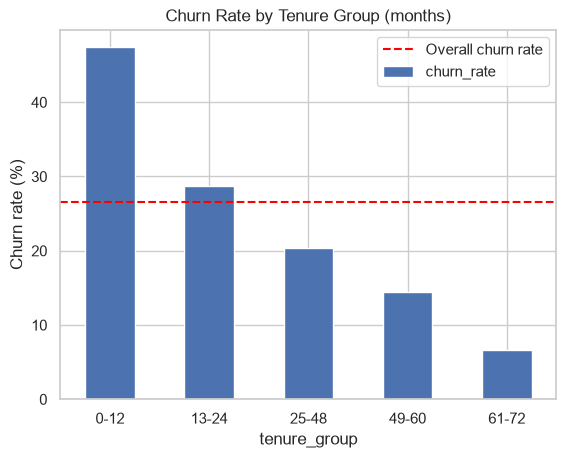

In [11]:
# Churn rate by tenure group (months)
tenure = df_clean.groupby("tenure_group", observed=True)["Churn_flag"].agg(customers="count", churn_rate="mean")
tenure["churn_rate"] = (tenure["churn_rate"] * 100).round(1)
display(tenure)

tenure["churn_rate"].plot(kind="bar", rot=0, title="Churn Rate by Tenure Group (months)")
plt.axhline(overall_rate, color="red", linestyle="--", label="Overall churn rate")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.show()

In [12]:
# Share of all churned customers coming from each tenure group
churned_share = df_clean[df_clean["Churn_flag"] == 1]["tenure_group"].value_counts(normalize=True).sort_index() * 100
print(churned_share.round(1))

tenure_group
0-12     55.5
13-24    15.7
25-48    17.4
49-60     6.4
61-72     5.0
Name: proportion, dtype: float64


### Insight: Churn by Tenure

- Churn falls steadily with tenure: 47.4% in the first 12 months, down to 6.6% for customers with 61-72 months.
- Customers in their first year are 31.0% of the base but 55.5% of all churned customers.
- Tenure and contract type overlap strongly: 91.2% of customers in their first 12 months are on month-to-month contracts, versus 7.7% of customers with 61-72 months. Long-tenure customers are also survivors, so tenure and contract effects cannot be treated as independent.

### 5.3 Churn by Monthly Charges
Are customers who pay more per month more likely to leave?

,customers,churn_rate
monthly_group,,
<=35,1735,10.9
35-70,1725,23.9
70-90,1844,37.8
>90,1739,32.8


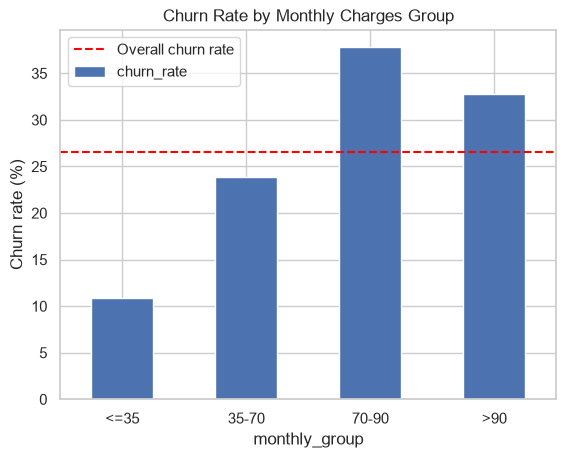

In [13]:
# Churn rate by monthly charges group
monthly = df_clean.groupby("monthly_group", observed=True)["Churn_flag"].agg(customers="count", churn_rate="mean")
monthly["churn_rate"] = (monthly["churn_rate"] * 100).round(1)
display(monthly)

monthly["churn_rate"].plot(kind="bar", rot=0, title="Churn Rate by Monthly Charges Group")
plt.axhline(overall_rate, color="red", linestyle="--", label="Overall churn rate")
plt.ylabel("Churn rate (%)")
plt.legend()
plt.show()

In [14]:
# Verify the actual range of MonthlyCharges in each group
df_clean.groupby('monthly_group', observed=True)['MonthlyCharges'].agg(['min', 'max', 'count'])

,min,max,count
monthly_group,,,
<=35,18.25,35.00,1735
35-70,35.05,70.00,1725
70-90,70.05,90.00,1844
>90,90.05,118.75,1739


In [15]:
# Verify churner count and churner share by monthly charges group
churners = df_clean[df_clean['Churn_flag'] == 1].groupby('monthly_group', observed=True).size()
print(churners)
print(churners.sum())
print((churners / churners.sum() * 100).round(1))

monthly_group
<=35     189
35-70    413
70-90    697
>90      570
dtype: int64
1869
monthly_group
<=35     10.1
35-70    22.1
70-90    37.3
>90      30.5
dtype: float64


### Insight: Churn by Monthly Charges

- Churn rate increases from 10.9% (<=35 USD) to 37.8% (70-90 USD), then declines slightly to 32.8% (>90 USD). The relationship is not linear.
- The <=35 USD group holds 24.6% of customers but only 10.1% of churners.
- The 70-90 USD and >90 USD groups together hold 50.9% of customers but 67.8% of churners.
- Group boundaries are upper-inclusive (for example, 35-70 means above 35 up to and including 70).
- This is an association only. Monthly charges may reflect other factors (such as service type or contract), which are examined in the next section.

### 5.4 Churn by Internet Service

This section compares churn across internet service types. Customers without internet service are kept as a separate group.

In [16]:
# Churn rate by internet service type
internet = df_clean.groupby("InternetService")["Churn_flag"].agg(customers="count", churners="sum", churn_rate="mean")
internet["churn_rate"] = (internet["churn_rate"] * 100).round(1)
display(internet)

,customers,churners,churn_rate
InternetService,,,
DSL,2421,459,19.0
Fiber optic,3096,1297,41.9
No,1526,113,7.4


In [17]:
# Check how internet service types are distributed across monthly charges groups
pd.crosstab(df_clean["monthly_group"], df_clean["InternetService"])

InternetService,DSL,Fiber optic,No
monthly_group,,,
<=35,209,0,1526
35-70,1613,112,0
70-90,552,1292,0
>90,47,1692,0


In [18]:
# Churn rate by monthly charges group and internet service type
within = df_clean.groupby(["monthly_group", "InternetService"], observed=True)["Churn_flag"].agg(customers="count", churn_rate="mean")
within["churn_rate"] = (within["churn_rate"] * 100).round(1)
display(within)

customers  churn_rate
monthly_group InternetService                       
<=35          DSL                    209        36.4
              No                    1526         7.4
35-70         DSL                   1613        21.3
              Fiber optic            112        62.5
70-90         DSL                    552         7.1
              Fiber optic           1292        50.9
>90           DSL                     47         2.1
              Fiber optic           1692        33.6

### Insight: Churn by Internet Service

- Fiber optic customers have the highest churn rate (41.9%), about 2.2 times the DSL rate (19.0%).
- Fiber optic customers make up 44.0% of the customer base but 69.4% of all churners.
- Customers without internet service have the lowest churn rate (7.4%) and account for 6.0% of churners.
- Internet service type and monthly charges overlap strongly: all customers without internet are in the <=35 group (88.0% of that group), and 97.3% of the >90 group use Fiber optic.
- Within the same internet service type, churn falls as monthly charges rise (DSL: 36.4% to 2.1%; Fiber optic: 62.5% to 33.6%). The overall rise in churn with charges in Section 5.3 therefore largely reflects the mix of services.
- In the 70-90 group, where both types have enough customers, Fiber optic churn (50.9%, n = 1,292) is far above DSL churn (7.1%, n = 552).
- Groups with fewer than 120 customers (Fiber optic in 35-70, DSL in >90) are too small to interpret.
- These are associations only. They do not show that price or service type causes churn.

### 5.5 Churn by Add-on Services

This section compares churn for add-on services among customers who have internet service. Customers without internet service are excluded because they are not eligible for these add-ons.

In [19]:
# Create the internet-only subset and verify it
df_internet = df_clean[df_clean["InternetService"] != "No"]
print(df_internet.shape)
print(df_internet["Churn_flag"].sum())
print((df_internet["Churn_flag"].mean() * 100).round(1))

(5517, 24)
1756
31.8


In [20]:
# Churn rate by add-on service (internet customers only)
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

for col in addons:
    print(col)
    result = df_internet.groupby(col)["Churn_flag"].agg(customers="count", churners="sum", churn_rate="mean")
    result["churn_rate"] = (result["churn_rate"] * 100).round(1)
    display(result)

OnlineSecurity


,customers,churners,churn_rate
OnlineSecurity,,,
No,3498,1461,41.8
Yes,2019,295,14.6


OnlineBackup


,customers,churners,churn_rate
OnlineBackup,,,
No,3088,1233,39.9
Yes,2429,523,21.5


DeviceProtection


,customers,churners,churn_rate
DeviceProtection,,,
No,3095,1211,39.1
Yes,2422,545,22.5


... (2 outputs left out)

StreamingTV


,customers,churners,churn_rate
StreamingTV,,,
No,2810,942,33.5
Yes,2707,814,30.1


StreamingMovies


,customers,churners,churn_rate
StreamingMovies,,,
No,2785,938,33.7
Yes,2732,818,29.9


In [21]:
# Churn rate by add-on and internet service type (OnlineSecurity and TechSupport)
for col in ["OnlineSecurity", "TechSupport"]:
    print(col)
    result = df_internet.groupby(["InternetService", col])["Churn_flag"].agg(customers="count", churn_rate="mean")
    result["churn_rate"] = (result["churn_rate"] * 100).round(1)
    display(result)

OnlineSecurity


customers  churn_rate
InternetService OnlineSecurity                       
DSL             No                   1241        28.0
                Yes                  1180         9.5
Fiber optic     No                   2257        49.4
                Yes                   839        21.8

TechSupport


customers  churn_rate
InternetService TechSupport                       
DSL             No                1243        27.8
                Yes               1178         9.7
Fiber optic     No                2230        49.4
                Yes                866        22.6

In [22]:
# Churn rate by contract type and add-on (OnlineSecurity and TechSupport), internet customers only
for col in ["OnlineSecurity", "TechSupport"]:
    print(col)
    result = df_internet.groupby(["Contract", col])["Churn_flag"].agg(customers="count", churn_rate="mean")
    result["churn_rate"] = (result["churn_rate"] * 100).round(1)
    display(result)

OnlineSecurity


customers  churn_rate
Contract       OnlineSecurity                       
Month-to-month No                   2631        51.0
               Yes                   720        29.6
One year       No                    557        17.4
               Yes                   552        10.9
Two year       No                    310         6.8
               Yes                   747         2.9

TechSupport


customers  churn_rate
Contract       TechSupport                       
Month-to-month No                2680        50.4
               Yes                671        30.7
One year       No                 557        14.7
               Yes                552        13.6
Two year       No                 236         5.9
               Yes                821         3.5

### Insight: Churn by Add-on Services

- Among customers with internet service, the baseline churn rate is 31.8% (1,756 of 5,517 customers). This is the correct comparison for add-on analysis.
- OnlineSecurity and TechSupport show the strongest associations. Customers without OnlineSecurity churn at 41.8% versus 14.6% with it. Customers without TechSupport churn at 41.6% versus 15.2% with it.
- OnlineBackup (39.9% vs 21.5%) and DeviceProtection (39.1% vs 22.5%) show smaller gaps. They were not tested by internet type or contract.
- StreamingTV and StreamingMovies show weak associations (33.5% vs 30.1% and 33.7% vs 29.9%).
- Customers with OnlineSecurity or TechSupport are much less likely to be on a month-to-month contract (35.7% and 32.8%, compared with 75.2% and 77.2% of customers without them). Part of the gap above therefore reflects contract type.
- Within month-to-month contracts, the gap remains about 20 percentage points (OnlineSecurity: 51.0% vs 29.6%; TechSupport: 50.4% vs 30.7%). Within one-year and two-year contracts, churn is low and the gaps are small (1.1 to 6.5 percentage points).
- These are associations only. Tenure was not controlled, and customers who choose add-ons may differ in other ways. The data does not show that add-ons reduce churn.

### 5.6 Churn by Tenure and Contract Type

Tenure and contract type are strongly related. This section checks whether the tenure pattern holds within each contract type.

In [23]:
# Check how contract types are distributed across tenure groups
pd.crosstab(df_clean["tenure_group"], df_clean["Contract"])

Contract,Month-to-month,One year,Two year
tenure_group,,,
0-12,1994,124,68
13-24,737,197,90
25-48,802,518,274
49-60,234,321,277
61-72,108,313,986


In [24]:
# Churn rate by tenure group and contract type
tc = df_clean.groupby(["tenure_group", "Contract"], observed=True)["Churn_flag"].agg(customers="count", churn_rate="mean")
tc["churn_rate"] = (tc["churn_rate"] * 100).round(1)
display(tc)

customers  churn_rate
tenure_group Contract                             
0-12         Month-to-month       1994        51.4
             One year              124        10.5
             Two year               68         0.0
13-24        Month-to-month        737        37.7
             One year              197         8.1
             Two year               90         0.0
25-48        Month-to-month        802        32.9
             One year              518        10.6
             Two year              274         2.2
49-60        Month-to-month        234        27.8
             One year              321        13.7
             Two year              277         4.0
61-72        Month-to-month        108        22.2
             One year              313        12.1
             Two year              986         3.1

In [25]:
# Verify churners among month-to-month customers in their first 12 months
segment = df_clean[(df_clean["tenure_group"] == "0-12") & (df_clean["Contract"] == "Month-to-month")]
print(len(segment))
print(segment["Churn_flag"].sum())
print((segment["Churn_flag"].sum() / df_clean["Churn_flag"].sum() * 100).round(1))

1994


1024


54.8


### Insight: Churn by Tenure and Contract Type

- Within month-to-month contracts, churn falls with tenure, from 51.4% (0-12 months) to 22.2% (61-72 months). The 61-72 month group has only 108 customers.
- Within one-year contracts, churn stays between 8.1% and 13.7% in every tenure group, with no steady decline. Two-year contracts have low churn in every tenure group (0.0% to 4.0%).
- In the first 12 months, month-to-month churn (51.4%) is far above one-year churn (10.5%, n = 124). Two-year groups in the 0-12 and 13-24 month ranges have no churners, but they have only 68 and 90 customers, which is too few to draw conclusions.
- The overall decline in churn with tenure therefore combines a decline within month-to-month contracts and a shift toward longer contracts among long-tenure customers.
- Month-to-month customers in their first 12 months (1,994 customers, 28.3% of the base) account for 1,024 churners, or 54.8% of all churners.
- These are associations only.

## 6. Key Findings

Overall, 1,869 of 7,043 customers churned (26.54%). The findings below summarize where churn is concentrated. All findings are descriptive associations, not causal effects.

1. **Contract type:** Month-to-month customers churn at 42.7%, compared with 11.3% (one year) and 2.8% (two year). They account for 88.6% of all churners.
2. **Tenure:** Customers in their first 12 months churn at 47.4%. This group is 31.0% of customers but 55.5% of churners. Churn falls steadily with tenure, to 6.6% for customers with 61-72 months.
3. **Monthly charges:** Churn rises from 10.9% (<=35 USD) to 37.8% (70-90 USD), then falls to 32.8% (>90 USD). This pattern largely reflects service mix: within the same internet type, churn falls as charges rise.
4. **Internet service:** Fiber optic customers churn at 41.9%, versus 19.0% for DSL and 7.4% for customers without internet. Fiber optic is 44.0% of customers but 69.4% of churners. In the 70-90 USD group, Fiber optic churn is 50.9% versus 7.1% for DSL.
5. **Add-on services (internet customers, baseline 31.8%):** Customers without OnlineSecurity or TechSupport churn at 41.8% and 41.6%, versus 14.6% and 15.2% with them. Part of this gap reflects contract type. Within month-to-month contracts, the gap is about 20 percentage points. StreamingTV and StreamingMovies show weak associations.
6. **Tenure and contract together:** Churn falls with tenure within month-to-month contracts (51.4% to 22.2%) but stays flat within one-year contracts (8.1% to 13.7%). Month-to-month customers in their first 12 months are 28.3% of customers but 54.8% of churners.

## 7. Recommendations

Each recommendation is linked to a finding above. Because the analysis is descriptive, the recommendations should be tested in small pilots before a full rollout.

1. **Target month-to-month customers, starting with new ones.** Month-to-month customers account for 88.6% of all churners. Those in their first 12 months (1,994 customers) churn at 51.4% and account for 54.8% of all churners. Combine early check-ins with an incentive to move to a one-year or two-year contract, and compare results with a control group.
2. **Investigate the Fiber optic customer experience.** Fiber optic churn is 41.9% and stays far above DSL at the same price level (50.9% vs 7.1% in the 70-90 USD group). The data cannot explain why. Use customer feedback, service quality data, and competitor pricing to find the reasons.
3. **Pilot OnlineSecurity and TechSupport offers for month-to-month internet customers without them.** The gap persists within this contract type (about 20 percentage points), but tenure and other factors were not controlled. A trial with a control group is needed to see whether the offers reduce churn.
4. **Do not prioritize streaming add-ons as a retention tool.** Their association with churn is weak (3-4 percentage points).

## 8. Limitations and Assumptions

**Data and cleaning**
- The dataset is a single snapshot of 7,043 customers from the IBM Telco sample. It has no dates, so trends over time and seasonality cannot be examined.
- 11 blank TotalCharges values were replaced with 0. All 11 customers have tenure = 0, so these are new customers with no billing yet.
- "No internet service" and "No phone service" were kept as separate categories. Add-on analysis (Section 5.5) uses only customers with internet service (5,517 customers, baseline churn 31.8%).

**Method**
- The analysis is descriptive. All findings are associations and do not show that any factor causes churn.
- Groups were compared one or two variables at a time. Variables such as contract, tenure, internet service, and monthly charges overlap strongly (Sections 5.3, 5.5, and 5.6), and no method was used to isolate the effect of a single factor.
- Monthly charges groups (<=35, 35-70, 70-90, >90 USD) and tenure groups were set manually. Different boundaries could change how the patterns look.
- Several subgroups are small (for example, Fiber optic in the 35-70 USD group with 112 customers, and two-year contracts in the first 24 months with 68 and 90 customers). These were not interpreted.
- OnlineBackup, DeviceProtection, and the streaming services were not tested by internet type or contract. Tenure was not controlled in the add-on analysis.
- Customers with long tenure are survivors: they stayed, so their churn rate reflects those who remained.

**Recommendations**
- The recommendations are hypotheses for small pilots with control groups. This dataset does not contain cost, revenue, or campaign data, so the financial impact of any recommendation cannot be estimated.

**Potential improvements**
- Test the main patterns statistically (for example, chi-square tests) and measure the strength of each association.
- Use a multivariate model, such as logistic regression, to separate the effects of overlapping factors. This is outside the scope of this project.
- Add customer feedback, service quality, and pricing data to explain the Fiber optic result.